# Run 02: where does the unlearn-loss drop come from?

**Run:** `lapa-12b-instruct`, `--no-split --loss_positions words --beta 1 --lr 5e-4 --alpha 5`, layer 7 (trained: 5, 6, 7 `down_proj`), 257 steps.

The unlearn loss falls from ≈3,100 to ≈2,300. Adaptive RMU's target is $c = \beta \, \lVert a_0 \rVert \, u$, so the loss can drop for two quite different reasons:

1. **Shrinking:** the forget activations get shorter but keep their direction. Cheap, and not misdirection.
2. **Rotation:** the forget activations turn towards the random direction $u$. This is what RMU is meant to do.

The question is how much of the drop each one explains.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

H = 3840  # hidden size of Lapa 12B (Gemma 3)
BETA = 1.0

d = pd.read_csv("02logs.csv")
d.head()

,step,loss,unlearn_loss,retain_loss,grad_mean,forget_word_norm,forget_other_norm,target_word_norm,unlearn_cosine_sim,retain_cosine_sim
0,0,3132.916748,3132.916748,0.000000,0.076660,2429.567139,35313.906250,2430.043457,1.000000,1.000000
1,1,3481.116455,2142.199219,1338.917236,0.183594,1552.402954,19097.457031,2388.777100,0.969012,0.970835
2,2,4019.715820,3432.039307,587.676575,0.203125,2540.324219,17480.865234,2477.650391,0.991040,0.990610
3,3,4310.924316,2196.006348,2114.917969,0.291016,1463.808716,46308.824219,2415.971191,0.876929,0.866910
4,4,3392.384766,3084.214355,308.170410,0.107422,2377.327393,14980.269531,2448.016113,0.992034,0.991831


## Decomposing the loss

For one word token, write $a$ for its updated activation, $a_0$ for its frozen one, and $\theta$ for the angle between $a$ and the control direction $u$. With $\lVert c \rVert = \beta \lVert a_0 \rVert$ and $k = \lVert a \rVert / \lVert a_0 \rVert$:

$$
L = \frac{\lVert a - c \rVert^2}{H}
  = \frac{\lVert a_0 \rVert^2}{H}\,\bigl(k^2 + \beta^2 - 2 \beta k \cos\theta\bigr).
$$

`losses.csv` logs $\lVert a \rVert$ (`forget_word_norm`), $\lVert c \rVert$ (`target_word_norm`) and $L$ (`unlearn_loss`), so we can solve for $\cos\theta$. This gives two counterfactual losses:

- **no change:** $k = 1$ and $\cos\theta = \cos\theta_0$ (the value at step 0, before any update)
- **shrink only:** the observed $k$, with $\cos\theta = \cos\theta_0$, i.e. no rotation

*Approximation:* the CSV holds batch means of per-token norms, not per-token values. This is fine as long as word norms vary little within a batch (pilot 2: std ≈ 2%).

In [2]:
a0 = d.target_word_norm / BETA                       # frozen word norm
d["k"] = d.forget_word_norm / a0                        # norm ratio updated / frozen
d["cos_ac"] = (d.k**2 + BETA**2 - H * d.unlearn_loss / a0**2) / (2 * BETA * d.k)
cos0 = d.cos_ac.iloc[0]

d["loss_no_change"] = a0**2 / H * (1 + BETA**2 - 2 * BETA * cos0)
d["loss_shrink_only"] = a0**2 / H * (d.k**2 + BETA**2 - 2 * BETA * d.k * cos0)

print(f"cos(a, u) at step 0: {cos0:.3f}  (random direction: about orthogonal)")

cos(a, u) at step 0: -0.019  (random direction: about orthogonal)


In [3]:
cols = ["unlearn_loss", "loss_no_change", "loss_shrink_only", "k", "cos_ac",
        "unlearn_cosine_sim", "retain_cosine_sim"]
blocks = d.groupby(pd.cut(d.step, [-1, 0, 50, 100, 150, 200, 257]), observed=True)[cols].mean()
blocks.index = ["step 0", "1-50", "51-100", "101-150", "151-200", "201-256"]
blocks.round(3)

,unlearn_loss,loss_no_change,loss_shrink_only,k,cos_ac,unlearn_cosine_sim,retain_cosine_sim
step 0,3132.917,3133.531,3132.917,1.000,-0.019,1.000,1.000
1-50,2564.265,3153.430,2690.270,0.838,0.030,0.985,0.986
51-100,2434.699,3148.902,2666.230,0.833,0.071,0.989,0.989
101-150,2379.390,3149.075,2655.098,0.829,0.089,0.988,0.989
151-200,2330.671,3126.009,2629.276,0.826,0.099,0.985,0.989
201-256,2335.285,3162.775,2652.124,0.823,0.105,0.983,0.988


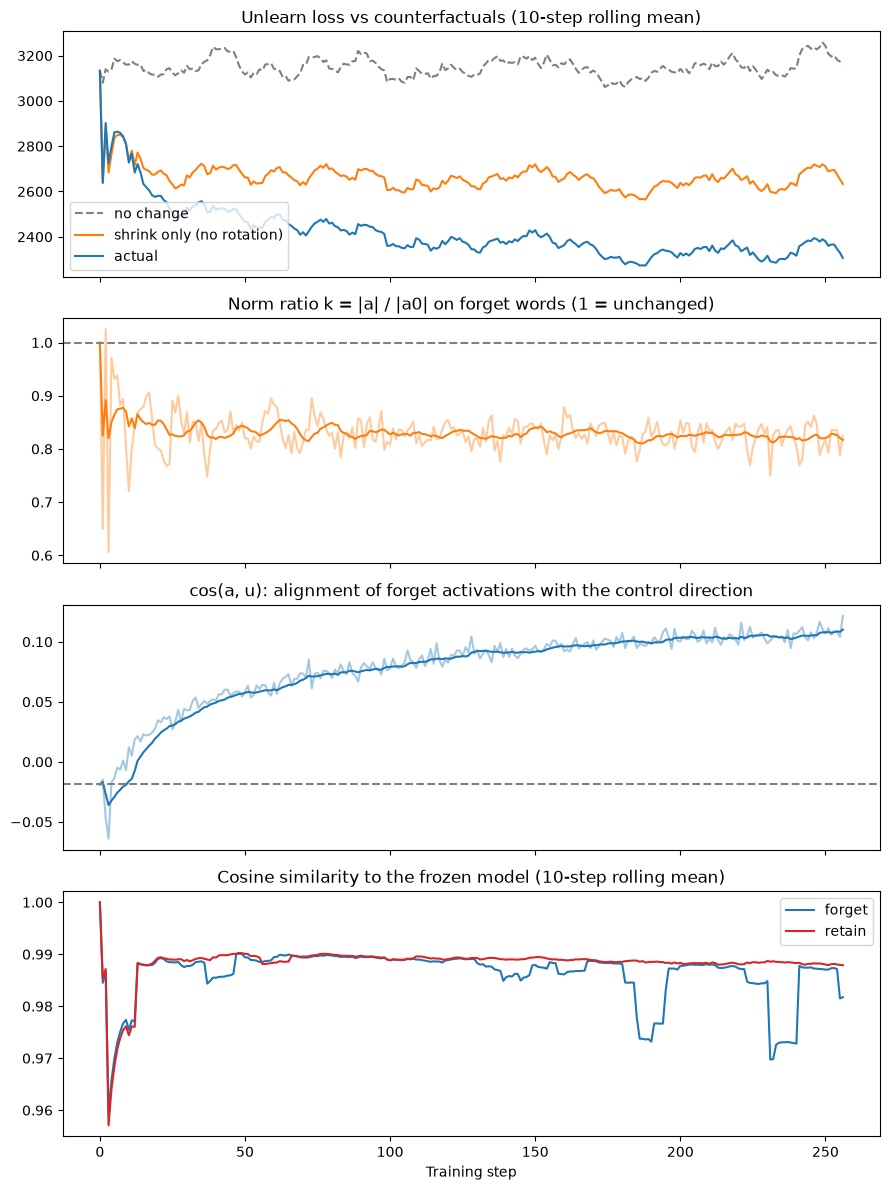

In [4]:
def smooth(s):
    return s.rolling(10, min_periods=1).mean()

fig, axes = plt.subplots(4, 1, figsize=(9, 12), sharex=True)

ax = axes[0]
ax.plot(d.step, smooth(d.loss_no_change), label="no change", color="grey", ls="--")
ax.plot(d.step, smooth(d.loss_shrink_only), label="shrink only (no rotation)", color="tab:orange")
ax.plot(d.step, smooth(d.unlearn_loss), label="actual", color="tab:blue")
ax.set_title("Unlearn loss vs counterfactuals (10-step rolling mean)")
ax.legend()

ax = axes[1]
ax.plot(d.step, d.k, color="tab:orange", alpha=0.4)
ax.plot(d.step, smooth(d.k), color="tab:orange")
ax.axhline(1, color="grey", ls="--")
ax.set_title("Norm ratio k = |a| / |a0| on forget words (1 = unchanged)")

ax = axes[2]
ax.plot(d.step, d.cos_ac, color="tab:blue", alpha=0.4)
ax.plot(d.step, smooth(d.cos_ac), color="tab:blue")
ax.axhline(cos0, color="grey", ls="--")
ax.set_title("cos(a, u): alignment of forget activations with the control direction")

ax = axes[3]
ax.plot(d.step, smooth(d.unlearn_cosine_sim), label="forget", color="tab:blue")
ax.plot(d.step, smooth(d.retain_cosine_sim), label="retain", color="tab:red")
ax.set_title("Cosine similarity to the frozen model (10-step rolling mean)")
ax.set_xlabel("Training step")
ax.legend()

fig.tight_layout()
fig.savefig("02_loss_decomposition.png", dpi=120)

## How much of the drop is shrinking?
Measured over the last 50 steps, after the initial jolt has settled.

In [5]:
last = d.iloc[-50:].mean()
total = last.loss_no_change - last.unlearn_loss
by_shrink = last.loss_no_change - last.loss_shrink_only
by_rotation = last.loss_shrink_only - last.unlearn_loss

print(f"drop vs no change: {total:7.0f}  ({total / last.loss_no_change:.0%} of the loss)")
print(f"  from shrinking:  {by_shrink:7.0f}  ({by_shrink / total:.0%} of the drop)")
print(f"  from rotation:   {by_rotation:7.0f}  ({by_rotation / total:.0%} of the drop)")
print(f"norm ratio k: {last.k:.3f}   cos(a, u): {cos0:.3f} -> {last.cos_ac:.3f}")
print(f"cosine to frozen: forget {last.unlearn_cosine_sim:.4f}, retain {last.retain_cosine_sim:.4f}")

drop vs no change:     829  (26% of the loss)
  from shrinking:      512  (62% of the drop)
  from rotation:       317  (38% of the drop)
norm ratio k: 0.823   cos(a, u): -0.019 -> 0.105
cosine to frozen: forget 0.9828, retain 0.9882


## Conclusions

- **Most of the drop is shrinking.** Over the last 50 steps the loss is ≈ 830 below the no-change value. About 60% of that comes from forget word activations shrinking by ≈ 18% ($k \approx 0.82$), and about 40% from rotation.
- **The shrinking happens all at once.** $k$ falls in the first few steps (the step-1 jolt, $k \approx 0.65$), then stays flat at ≈ 0.82–0.84.
- **The rotation is real but small, and it keeps growing.** $\cos(a, u)$ rises steadily from ≈ −0.02 to ≈ 0.10, about 7° towards $u$ out of the 90° needed to reach the target. The slow downward trend of the loss after the jolt comes from this rotation, not from further shrinking.
- **No real selectivity yet.** In the last 50 steps the mean forget cosine to the frozen model (≈ 0.983) is below the retain cosine (≈ 0.988), but the median gap is only −0.0006. The whole difference comes from 7 single-batch dips (steps 37, 181, 185, 186, 223, 231, 255; down to 0.84 at step 231), where only the forget activations moved. Those batches are worth inspecting: they're the only places where the edit acts on forget data alone.

**Caveats:** this is computed from batch-mean norms, not per token. Retain norms aren't logged, so it's unknown whether the retain activations shrank too. Logging `retain_word_norm` would settle that. A longer run (more epochs, or a slightly higher lr) would show whether the rotation keeps growing or levels off.